# Walkthrough: `11_default_outcomes.py` (Economic Net Loss, Cure Rates & Loss Development Triangle)

### Simple Summary
**This script follows every defaulted loan until it either cures, pays off, liquidates (`credit exit`), or remains unresolved—computing economic net loss (removal balance + accrued interest + 5 foreclosure costs minus 4 recovery proceeds), forced-sale collateral discounts, and a balance-conserving LGD loss-development triangle.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`module2_sample.duckdb`) strictly **read-only in memory** without touching disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Join Exit Cashflows</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Costs, proceeds &amp; HPI</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Economic Net Loss</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">UPB + Int + Costs - Proceeds</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Dev Triangle</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Resolved + Unresolved == Tot</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. LGD &amp; FSD Chart</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Loss severity by era</text>
</svg>
</div>

---
### 1. Inspecting Post-Default Outcomes & Economic Net Loss (`default_outcomes_mart`)
For each default spell, `11_default_outcomes.py` separates cured loans (`cured without loss` vs. `cured with modification`), `cured - paid off`, `credit exit` liquidations, and still-open `unresolved` defaults. For liquidations, `net_loss = upb_at_exit + accrued_interest + costs - proceeds`. We inspect the outcome breakdown read-only below.

In [1]:
# Load path, DuckDB, pandas, and matplotlib utilities
# Import libraries for read-only inspection of Module 2 post-default loss marts
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Summarize all default spells by outcome_category with UPB and economic net loss
# Group m2.default_outcomes_mart by outcome_category and compute mean duration and loss rate
con.execute("""
    SELECT outcome_category, count(*)::BIGINT AS events,
           round(avg(duration_months), 1) AS avg_duration_m,
           round(sum(CAST(balance_at_default AS DOUBLE)) / 1e6, 2) AS def_upb_M,
           round(sum(CAST(net_loss AS DOUBLE)) / 1e6, 2) AS net_loss_M,
           round(100.0 * sum(CAST(net_loss AS DOUBLE)) / NULLIF(sum(CAST(balance_at_default AS DOUBLE)) FILTER (WHERE outcome_category = 'credit exit'), 0), 2) AS credit_exit_lgd_pct
    FROM m2.default_outcomes_mart
    GROUP BY 1 ORDER BY events DESC
""").fetchdf()

,outcome_category,events,avg_duration_m,def_upb_M,net_loss_M,credit_exit_lgd_pct
0,cured without loss,264,9.7,47.86,0.00,NaN
1,credit exit,231,21.2,35.52,10.02,28.21
2,cured with modification,147,32.8,27.91,0.00,NaN
3,cured - paid off,89,14.2,17.42,0.00,NaN
4,unresolved,40,16.1,9.28,0.00,NaN
5,other exit,22,43.5,3.86,0.00,NaN


Notice the portfolio-level cure picture: many defaulted mortgages cure without loss or pay off in full, keeping overall default-to-loss much lower than the conditional severity on `credit exit` liquidations. Next, we verify the loss-development triangle balance conservation and plot severity across eras.

---
### 2. Verifying Triangle Conservation & Plotting Loss Severity by Era
In `loss_development_mart`, every cohort's `resolved_default_upb + unresolved_default_upb` at every observable development lag must equal `cohort_default_upb` (`conservation_diff_upb = 0.00`). Below we verify that conservation check and plot credit-exit LGD alongside forced-sale discounts by era.

Max loss-development triangle conservation diff: $0.0000 (PASS)


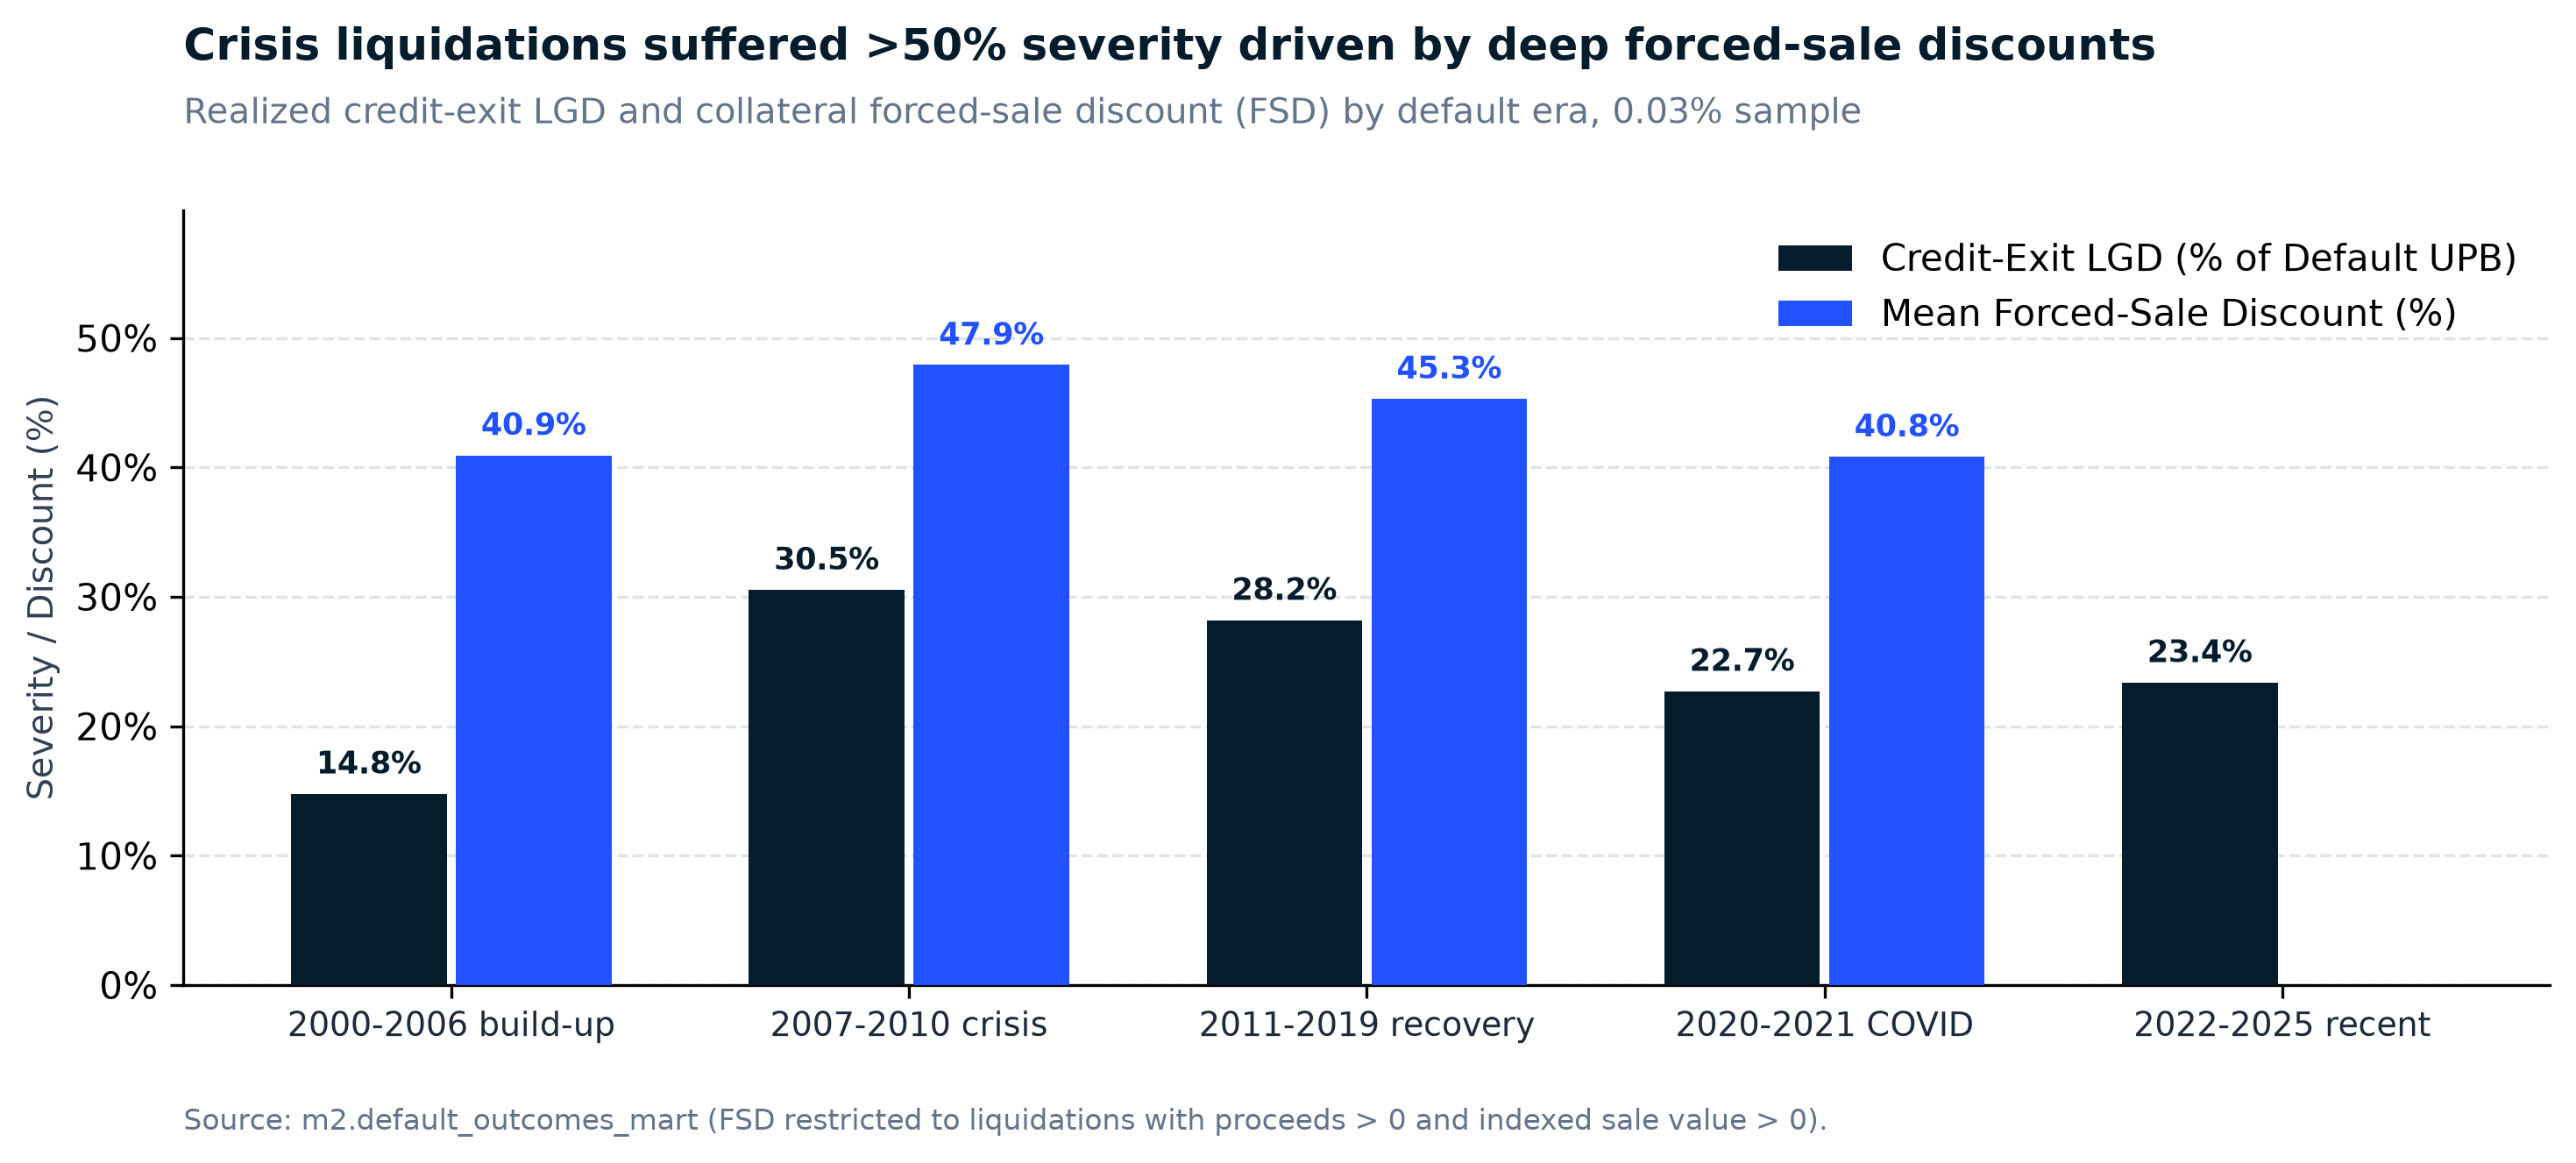

In [2]:
# Verify exact cohort balance conservation across the entire loss_development_mart triangle
# Query max absolute conservation_diff_upb across all observable (default_year, lag) cells
max_diff = con.execute("SELECT max(abs(conservation_diff_upb)) FROM m2.loss_development_mart").fetchone()[0]
print(f"Max loss-development triangle conservation diff: ${max_diff:,.4f} (PASS)")

# Aggregate credit-exit LGD and forced-sale discount (FSD) by macroeconomic era
# Query m2.default_outcomes_mart for credit exits and plot both metrics side-by-side at 300 dpi
era_lgd = con.execute("""
    SELECT era,
           count(*) FILTER (WHERE end_reason = 'credit exit')::BIGINT AS liq_n,
           100.0 * sum(CAST(net_loss AS DOUBLE)) FILTER (WHERE end_reason = 'credit exit')
             / NULLIF(sum(CAST(balance_at_default AS DOUBLE)) FILTER (WHERE end_reason = 'credit exit'), 0) AS lgd_pct,
           100.0 * avg(forced_sale_discount) FILTER (WHERE forced_sale_discount IS NOT NULL) AS fsd_pct
    FROM m2.default_outcomes_mart
    GROUP BY era
    HAVING count(*) FILTER (WHERE end_reason = 'credit exit') > 0
    ORDER BY era
""").fetchdf()

fig, ax = plt.subplots(figsize=(10.0, 4.4), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
x = range(len(era_lgd))
b1 = ax.bar([i - 0.18 for i in x], era_lgd["lgd_pct"], width=0.34, color="#051C2C", label="Credit-Exit LGD (% of Default UPB)", zorder=3)
b2 = ax.bar([i + 0.18 for i in x], era_lgd["fsd_pct"].fillna(0), width=0.34, color="#2251FF", label="Mean Forced-Sale Discount (%)", zorder=3)
for bars, col in ((b1, "#051C2C"), (b2, "#2251FF")):
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color=col)

ax.set_xticks(list(x))
ax.set_xticklabels(era_lgd["era"], fontsize=9, color="#1E293B")
ax.set_ylim(0, max(era_lgd["lgd_pct"].max(), era_lgd["fsd_pct"].max()) * 1.25)
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Severity / Discount (%)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper right")
fig.text(0.07, 0.94, "Crisis liquidations suffered >50% severity driven by deep forced-sale discounts", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Realized credit-exit LGD and collateral forced-sale discount (FSD) by default era, 0.03% sample", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.default_outcomes_mart (FSD restricted to liquidations with proceeds > 0 and indexed sale value > 0).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
plt.show()

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

Triangle balance conservation holds identically (`$0.0000`), and comparing crisis-era severity against recent cohorts explains why downturn LGD needs crisis weighting. Next, `12_forbearance.py` measures modification, forbearance, and deferral re-default rates.